<a href="https://colab.research.google.com/github/Krishan-42/Deep-Learning/blob/main/MNIST_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.optimizers import SGD

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [21]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing data:", x_test.shape)
print("Testing labels:", y_test.shape)

Training data: (60000, 28, 28)
Training labels: (60000,)
Testing data: (10000, 28, 28)
Testing labels: (10000,)


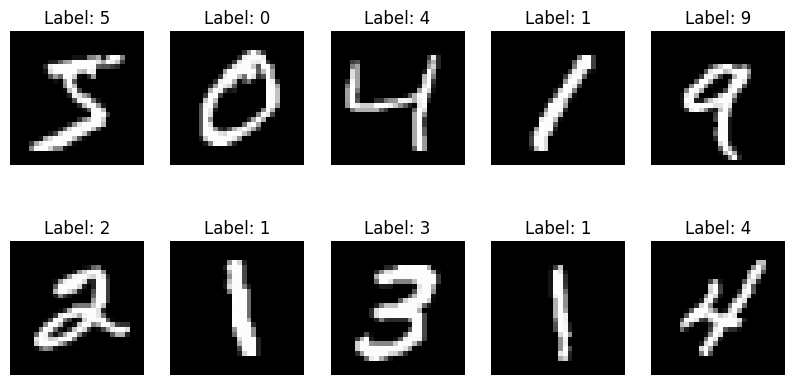

In [22]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

In [23]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [24]:
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

Minimum: 0.0
Maximum: 1.0


In [25]:
def create_model(learning_rate):

    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=SGD(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [26]:
model = create_model(0.01)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
learning_rates = [0.01, 0.001, 0.0001]

In [28]:
histories = {}
models = {}
results = []

for lr in learning_rates:

    print("\n" + "=" * 50)
    print(f"Training with Learning Rate = {lr}")
    print("=" * 50)

    # Create a new model
    model = create_model(lr)

    # Train the model
    history = model.fit(
        x_train,
        y_train,
        epochs=10,
        batch_size=32,
        validation_split=0.1,
        verbose=1
    )

    # Store model and history
    models[lr] = model
    histories[lr] = history

    # Final training accuracy
    train_accuracy = history.history['accuracy'][-1]

    # Final validation accuracy
    validation_accuracy = history.history['val_accuracy'][-1]

    # Test accuracy
    test_loss, test_accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    # Store results
    results.append([
        lr,
        train_accuracy,
        validation_accuracy,
        test_accuracy
    ])


Training with Learning Rate = 0.01
Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8311 - loss: 0.6787 - val_accuracy: 0.9145 - val_loss: 0.3249
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9020 - loss: 0.3522 - val_accuracy: 0.9282 - val_loss: 0.2636
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9149 - loss: 0.3016 - val_accuracy: 0.9355 - val_loss: 0.2324
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9237 - loss: 0.2704 - val_accuracy: 0.9418 - val_loss: 0.2107
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9305 - loss: 0.2471 - val_accuracy: 0.9475 - val_loss: 0.1939
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9355 - loss: 0.2280 - val_accuracy: 0.9520 - val_loss: 0.1813
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9405 - loss: 0.2118 - val_accuracy: 0.9558 - val_loss: 0.1684
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step 

In [29]:
results_df = pd.DataFrame(
    results,
    columns=[
        'Learning Rate',
        'Training Accuracy',
        'Validation Accuracy',
        'Test Accuracy'
    ]
)

results_df

,Learning Rate,Training Accuracy,Validation Accuracy,Test Accuracy
0,0.0100,0.950241,0.962167,0.9521
1,0.0010,0.891185,0.914500,0.9017
2,0.0001,0.755704,0.799667,0.7752


In [30]:
results_percentage = results_df.copy()

results_percentage[
    ['Training Accuracy',
     'Validation Accuracy',
     'Test Accuracy']
] *= 100

results_percentage

,Learning Rate,Training Accuracy,Validation Accuracy,Test Accuracy
0,0.0100,95.024073,96.216667,95.209998
1,0.0010,89.118516,91.450000,90.170002
2,0.0001,75.570369,79.966664,77.520001


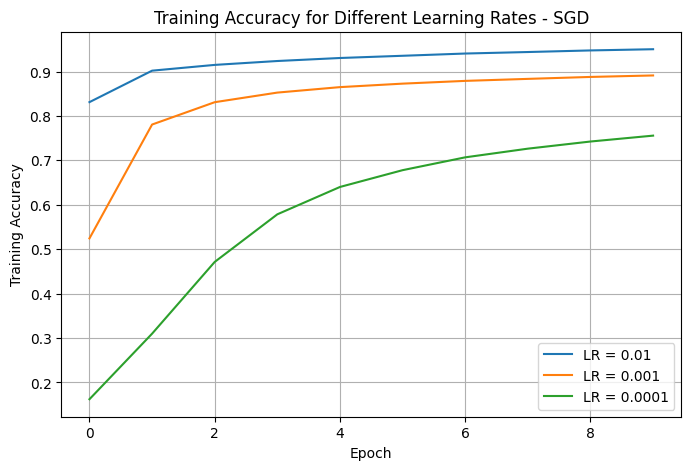

In [31]:
plt.figure(figsize=(8, 5))

for lr in learning_rates:
    plt.plot(
        histories[lr].history['accuracy'],
        label=f'LR = {lr}'
    )

plt.xlabel('Epoch')
plt.ylabel('Training Accuracy')
plt.title('Training Accuracy for Different Learning Rates - SGD')
plt.legend()
plt.grid(True)
plt.show()

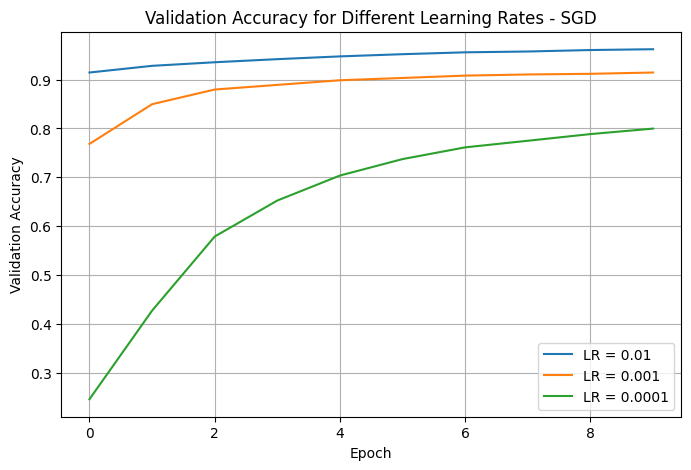

In [32]:
plt.figure(figsize=(8, 5))

for lr in learning_rates:
    plt.plot(
        histories[lr].history['val_accuracy'],
        label=f'LR = {lr}'
    )

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy for Different Learning Rates - SGD')
plt.legend()
plt.grid(True)
plt.show()

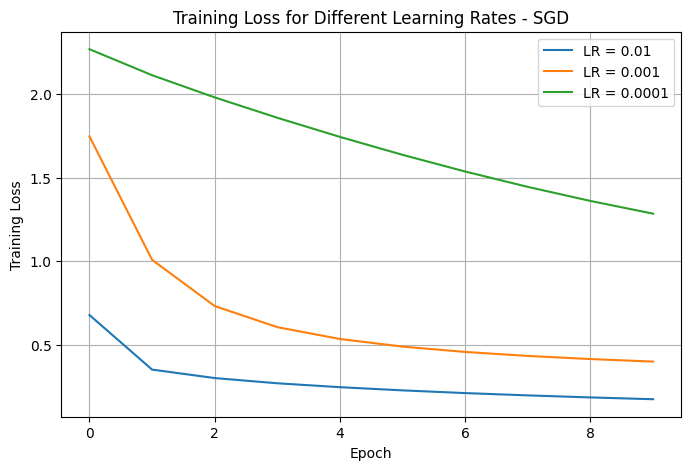

In [33]:
plt.figure(figsize=(8, 5))

for lr in learning_rates:
    plt.plot(
        histories[lr].history['loss'],
        label=f'LR = {lr}'
    )

plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Training Loss for Different Learning Rates - SGD')
plt.legend()
plt.grid(True)
plt.show()

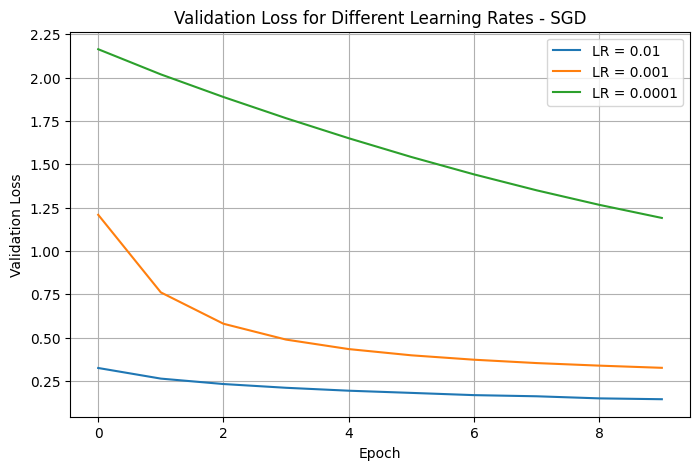

In [34]:
plt.figure(figsize=(8, 5))

for lr in learning_rates:
    plt.plot(
        histories[lr].history['val_loss'],
        label=f'LR = {lr}'
    )

plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Validation Loss for Different Learning Rates - SGD')
plt.legend()
plt.grid(True)
plt.show()

In [35]:
loss_results = []

for lr in learning_rates:

    train_loss = histories[lr].history['loss'][-1]
    validation_loss = histories[lr].history['val_loss'][-1]

    test_loss, test_accuracy = models[lr].evaluate(
        x_test,
        y_test,
        verbose=0
    )

    loss_results.append([
        lr,
        train_loss,
        validation_loss,
        test_loss
    ])

loss_df = pd.DataFrame(
    loss_results,
    columns=[
        'Learning Rate',
        'Training Loss',
        'Validation Loss',
        'Test Loss'
    ]
)

loss_df

,Learning Rate,Training Loss,Validation Loss,Test Loss
0,0.0100,0.175099,0.144752,0.169315
1,0.0010,0.400260,0.325911,0.366874
2,0.0001,1.284727,1.190541,1.225951


In [36]:
best_lr = results_df.loc[
    results_df['Test Accuracy'].idxmax(),
    'Learning Rate'
]

best_model = models[best_lr]

print("Best Learning Rate:", best_lr)

Best Learning Rate: 0.01


In [37]:
predictions = best_model.predict(x_test)

y_pred = np.argmax(predictions, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


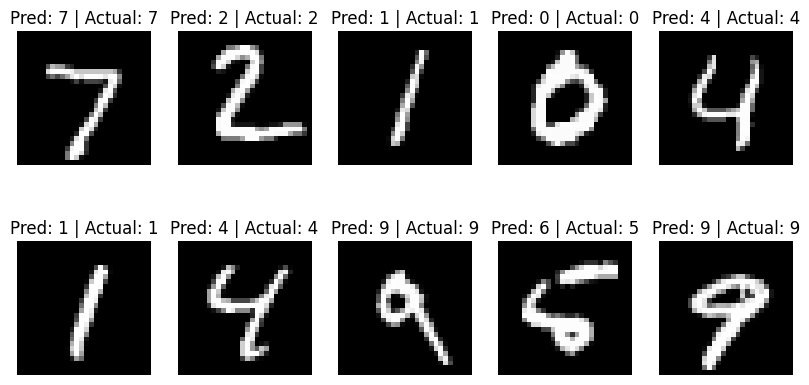

In [38]:
plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    predicted = y_pred[i]
    actual = y_test[i]

    plt.title(f"Pred: {predicted} | Actual: {actual}")
    plt.axis('off')

plt.show()

In [39]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

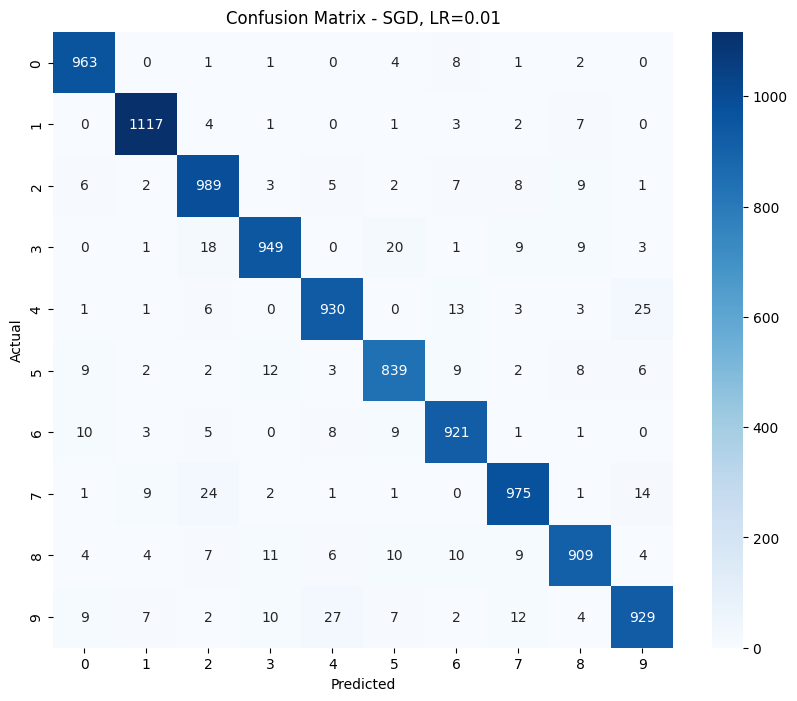

In [40]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - SGD, LR={best_lr}')

plt.show()

In [41]:
print("======================================")
print("       MNIST SGD EXPERIMENT")
print("======================================")

for _, row in results_percentage.iterrows():

    print(f"\nLearning Rate: {row['Learning Rate']}")
    print(f"Training Accuracy:   {row['Training Accuracy']:.2f}%")
    print(f"Validation Accuracy: {row['Validation Accuracy']:.2f}%")
    print(f"Test Accuracy:       {row['Test Accuracy']:.2f}%")

print("\n======================================")
print(f"Best Learning Rate: {best_lr}")
print("======================================")

       MNIST SGD EXPERIMENT

Learning Rate: 0.01
Training Accuracy:   95.02%
Validation Accuracy: 96.22%
Test Accuracy:       95.21%

Learning Rate: 0.001
Training Accuracy:   89.12%
Validation Accuracy: 91.45%
Test Accuracy:       90.17%

Learning Rate: 0.0001
Training Accuracy:   75.57%
Validation Accuracy: 79.97%
Test Accuracy:       77.52%

Best Learning Rate: 0.01
